
===== Información general =====
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 31 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   mean radius              569 non-null    float64
 1   mean texture             569 non-null    float64
 2   mean perimeter           569 non-null    float64
 3   mean area                569 non-null    float64
 4   mean smoothness          569 non-null    float64
 5   mean compactness         569 non-null    float64
 6   mean concavity           569 non-null    float64
 7   mean concave points      569 non-null    float64
 8   mean symmetry            569 non-null    float64
 9   mean fractal dimension   569 non-null    float64
 10  radius error             569 non-null    float64
 11  texture error            569 non-null    float64
 12  perimeter error          569 non-null    float64
 13  area error               569 non-null    float6

/var/folders/0n/g5l4v8c52nn4wxk7hl89vk3m0000gn/T/ipykernel_3689/1412112202.py:43: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x="diagnosis", palette="Set2")


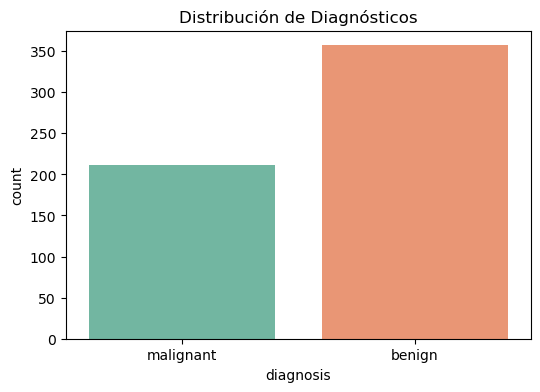

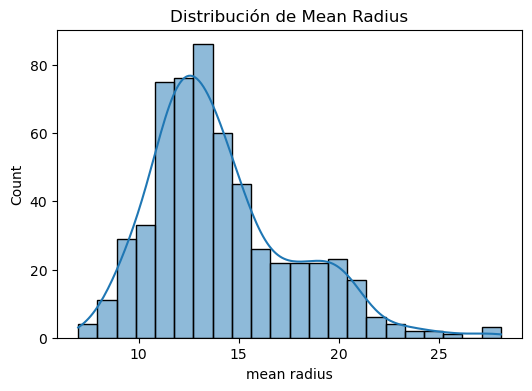

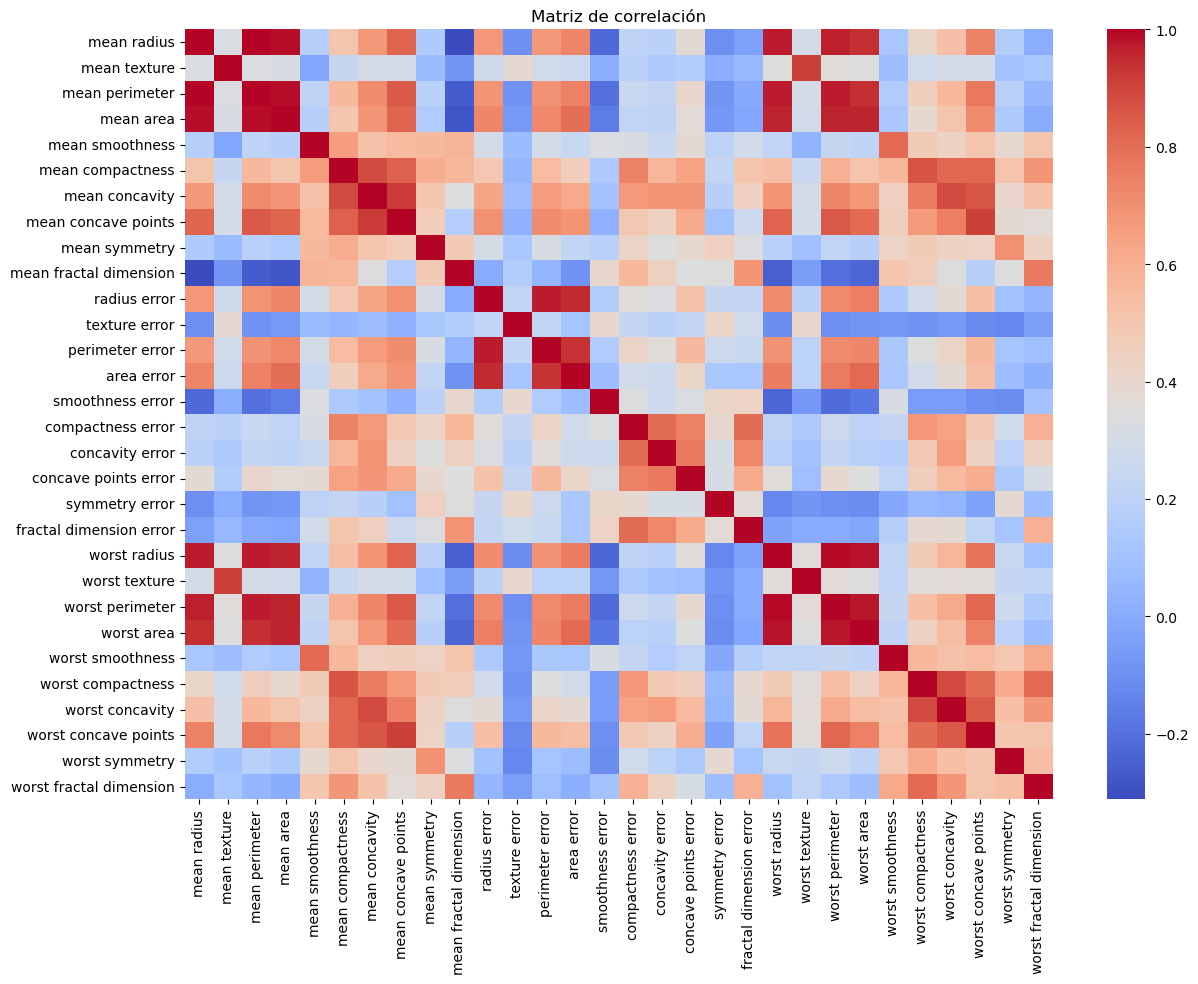

In [1]:
# =====================================
# 1. Importar librerías
# =====================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer

# =====================================
# 2. Cargar dataset Wisconsin
# =====================================
data = load_breast_cancer()

# Crear DataFrame
df = pd.DataFrame(data.data, columns=data.feature_names)
df["target"] = data.target

# Renombrar target a algo más interpretable
df["diagnosis"] = df["target"].map({0: "malignant", 1: "benign"})
df = df.drop(columns="target")

# =====================================
# 3. Información general
# =====================================
print("\n===== Información general =====")
print(df.info())

print("\n===== Primeras filas =====")
print(df.head())

print("\n===== Estadísticos descriptivos =====")
print(df.describe())

print("\n===== Distribución de la variable objetivo =====")
print(df["diagnosis"].value_counts())

# =====================================
# 4. Visualizaciones básicas
# =====================================
plt.figure(figsize=(6,4))
sns.countplot(data=df, x="diagnosis", palette="Set2")
plt.title("Distribución de Diagnósticos")
plt.show()

# Histograma de una variable
plt.figure(figsize=(6,4))
sns.histplot(df["mean radius"], kde=True)
plt.title("Distribución de Mean Radius")
plt.show()

# =====================================
# 5. Matriz de correlaciones
# =====================================
plt.figure(figsize=(14,10))
corr = df.drop(columns="diagnosis").corr()
sns.heatmap(corr, cmap="coolwarm", annot=False)
plt.title("Matriz de correlación")
plt.show()



Código completo: Train/Test + Árbol de Clasificación + Métricas + Importancias


===== Balanced Accuracy =====
0.9226190476190477

===== Accuracy =====
0.9210526315789473

===== Matriz de confusión =====
[[39  3]
 [ 6 66]]

===== Reporte de clasificación =====
              precision    recall  f1-score   support

   malignant       0.87      0.93      0.90        42
      benign       0.96      0.92      0.94        72

    accuracy                           0.92       114
   macro avg       0.91      0.92      0.92       114
weighted avg       0.92      0.92      0.92       114


===== Importancia de variables =====
                variable  importancia
20          worst radius     0.714332
27  worst concave points     0.118831
11         texture error     0.053907
21         worst texture     0.031473
26       worst concavity     0.016712
24      worst smoothness     0.012978
13            area error     0.012371
1           mean texture     0.011536
28        worst symmetry     0.010987
23            worst area     0.008652


/var/folders/0n/g5l4v8c52nn4wxk7hl89vk3m0000gn/T/ipykernel_3689/509589994.py:76: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


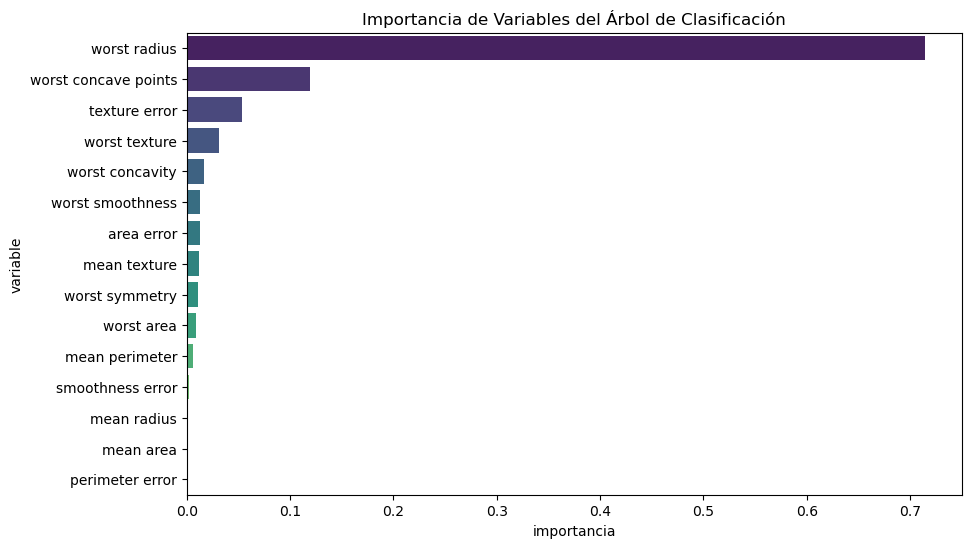

In [2]:
# =====================================
# 1. Importar librerías
# =====================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import balanced_accuracy_score, accuracy_score, confusion_matrix, classification_report

# =====================================
# 2. Cargar dataset
# =====================================
data = load_breast_cancer()
df = pd.DataFrame(data.data, columns=data.feature_names)
df["diagnosis"] = data.target  # 0 = malignant, 1 = benign

# Variables (X) y target (y)
X = df.drop(columns="diagnosis")
y = df["diagnosis"]

# =====================================
# 3. División train/test
# =====================================
X_train, X_test, y_train, y_test = train_test_split(
    X, y, 
    test_size=0.2, 
    random_state=42,
    stratify=y
)

# =====================================
# 4. Entrenar Árbol de Clasificación
# =====================================
arbol = DecisionTreeClassifier(
    criterion="gini",
    max_depth=5,               # limitar profundidad mejora generalización
    random_state=42
)

arbol.fit(X_train, y_train)

# =====================================
# 5. Predicción y métricas
# =====================================
y_pred = arbol.predict(X_test)

print("\n===== Balanced Accuracy =====")
print(balanced_accuracy_score(y_test, y_pred))

print("\n===== Accuracy =====")
print(accuracy_score(y_test, y_pred))

print("\n===== Matriz de confusión =====")
print(confusion_matrix(y_test, y_pred))

print("\n===== Reporte de clasificación =====")
print(classification_report(y_test, y_pred, target_names=["malignant", "benign"]))

# =====================================
# 6. Importancia de variables
# =====================================
importancias = pd.DataFrame({
    "variable": X.columns,
    "importancia": arbol.feature_importances_
}).sort_values(by="importancia", ascending=False)

print("\n===== Importancia de variables =====")
print(importancias.head(10))

# Gráfico de importancias
plt.figure(figsize=(10, 6))
sns.barplot(
    data=importancias.head(15),
    x="importancia",
    y="variable",
    palette="viridis"
)
plt.title("Importancia de Variables del Árbol de Clasificación")
plt.show()


##Código: Optimización de Parámetros del Árbol (GridSearchCV)

Fitting 5 folds for each of 192 candidates, totalling 960 fits

===== Mejores parámetros encontrados =====
{'criterion': 'gini', 'max_depth': 5, 'min_samples_leaf': 1, 'min_samples_split': 5}

===== Mejor score en validación cruzada =====
0.9384615384615385

===== Accuracy en TEST =====
0.9210526315789473

===== Matriz de confusión =====
[[39  3]
 [ 6 66]]

===== Reporte de clasificación =====
              precision    recall  f1-score   support

   malignant       0.87      0.93      0.90        42
      benign       0.96      0.92      0.94        72

    accuracy                           0.92       114
   macro avg       0.91      0.92      0.92       114
weighted avg       0.92      0.92      0.92       114


===== Variables más importantes =====
                variable  importancia
20          worst radius     0.718940
27  worst concave points     0.119597
11         texture error     0.054255
21         worst texture     0.043286
26       worst concavity     0.016819
24      w

/var/folders/0n/g5l4v8c52nn4wxk7hl89vk3m0000gn/T/ipykernel_3689/1057052027.py:96: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


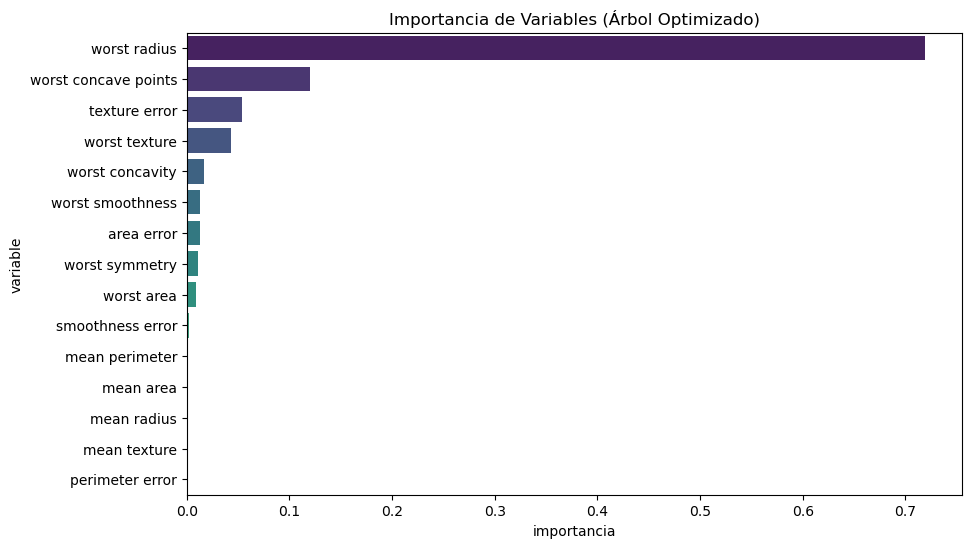

In [3]:
# =====================================
# 1. Importar librerías
# =====================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# =====================================
# 2. Cargar dataset
# =====================================
data = load_breast_cancer()
df = pd.DataFrame(data.data, columns=data.feature_names)
df["diagnosis"] = data.target  # 0 = malignant, 1 = benign

X = df.drop(columns="diagnosis")
y = df["diagnosis"]

# =====================================
# 3. División train/test
# =====================================
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# =====================================
# 4. Definir grilla de búsqueda de hiperparámetros
# =====================================
param_grid = {
    "criterion": ["gini", "entropy"],
    "max_depth": [2, 3, 5, 7, 10, None],
    "min_samples_split": [2, 5, 10, 20],
    "min_samples_leaf": [1, 2, 4, 8],
}

# Modelo base
dt = DecisionTreeClassifier(random_state=42)

# Grid Search
grid = GridSearchCV(
    estimator=dt,
    param_grid=param_grid,
    scoring="accuracy",
    cv=5,
    n_jobs=-1,
    verbose=1
)

grid.fit(X_train, y_train)

# =====================================
# 5. Resultados
# =====================================
print("\n===== Mejores parámetros encontrados =====")
print(grid.best_params_)

print("\n===== Mejor score en validación cruzada =====")
print(grid.best_score_)

# Modelo optimizado
best_tree = grid.best_estimator_

# Predicciones
y_pred = best_tree.predict(X_test)

print("\n===== Accuracy en TEST =====")
print(accuracy_score(y_test, y_pred))

print("\n===== Matriz de confusión =====")
print(confusion_matrix(y_test, y_pred))

print("\n===== Reporte de clasificación =====")
print(classification_report(y_test, y_pred, target_names=["malignant", "benign"]))

# =====================================
# 6. Importancia de variables
# =====================================
importancias = pd.DataFrame({
    "variable": X.columns,
    "importancia": best_tree.feature_importances_
}).sort_values(by="importancia", ascending=False)

print("\n===== Variables más importantes =====")
print(importancias.head(10))

# Gráfico
plt.figure(figsize=(10, 6))
sns.barplot(
    data=importancias.head(15),
    x="importancia",
    y="variable",
    palette="viridis"
)
plt.title("Importancia de Variables (Árbol Optimizado)")
plt.show()


###Comparación Árbol vs Random Forest (con bootstrap y agregación)


===== Accuracy Árbol optimizado =====
0.9210526315789473

===== Accuracy Random Forest =====
0.9473684210526315

===== OOB Score (Random Forest) =====
0.9560439560439561

===== Matriz de confusión RF =====
[[39  3]
 [ 3 69]]

===== Reporte de clasificación RF =====
              precision    recall  f1-score   support

           0       0.93      0.93      0.93        42
           1       0.96      0.96      0.96        72

    accuracy                           0.95       114
   macro avg       0.94      0.94      0.94       114
weighted avg       0.95      0.95      0.95       114


===== Top 10 variables más importantes (RF) =====
                variable  importancia
22       worst perimeter     0.137344
23            worst area     0.137312
27  worst concave points     0.115502
7    mean concave points     0.091774
20          worst radius     0.084111
0            mean radius     0.062741
2         mean perimeter     0.049680
6         mean concavity     0.044142
3            

/var/folders/0n/g5l4v8c52nn4wxk7hl89vk3m0000gn/T/ipykernel_3689/234302370.py:108: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


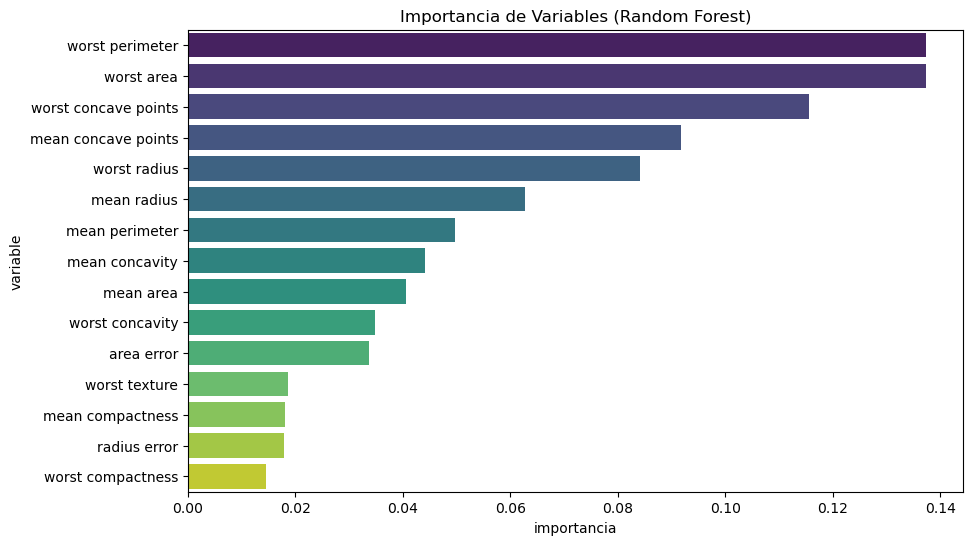



===== Comparación Final =====
             Modelo  Accuracy Test  OOB Score (solo RF)
0  Árbol Optimizado       0.921053                  NaN
1     Random Forest       0.947368             0.956044


In [4]:
# =====================================
# 1. Importar librerías
# =====================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# =====================================
# 2. Cargar dataset
# =====================================
data = load_breast_cancer()
df = pd.DataFrame(data.data, columns=data.feature_names)
df["diagnosis"] = data.target

X = df.drop(columns="diagnosis")
y = df["diagnosis"]

# =====================================
# 3. División train/test
# =====================================
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    stratify=y,
    random_state=42
)

# =====================================
# 4. Optimización del Árbol (GridSearch)
# =====================================
param_grid = {
    "criterion": ["gini", "entropy"],
    "max_depth": [2, 3, 5, 7, 10, None],
    "min_samples_split": [2, 5, 10, 20],
    "min_samples_leaf": [1, 2, 4, 8],
}

grid = GridSearchCV(
    DecisionTreeClassifier(random_state=42),
    param_grid,
    scoring="accuracy",
    cv=5,
    n_jobs=-1
)

grid.fit(X_train, y_train)
best_tree = grid.best_estimator_

# Predicción del Árbol
y_pred_tree = best_tree.predict(X_test)
acc_tree = accuracy_score(y_test, y_pred_tree)

# =====================================
# 5. Entrenar Random Forest (Bootstrap + Agregación)
# =====================================
rf = RandomForestClassifier(
    n_estimators=300,       # bosque grande
    max_features="sqrt",    # típico para RF
    bootstrap=True,         # BOOTSTRAP (muestras con reemplazo)
    oob_score=True,         # Out-of-bag para validar internamente
    random_state=42,
    n_jobs=-1
)

rf.fit(X_train, y_train)

# Predicción del Random Forest
y_pred_rf = rf.predict(X_test)
acc_rf = accuracy_score(y_test, y_pred_rf)

# =====================================
# 6. Resultados
# =====================================
print("\n===== Accuracy Árbol optimizado =====")
print(acc_tree)

print("\n===== Accuracy Random Forest =====")
print(acc_rf)

print("\n===== OOB Score (Random Forest) =====")
print(rf.oob_score_)

print("\n===== Matriz de confusión RF =====")
print(confusion_matrix(y_test, y_pred_rf))

print("\n===== Reporte de clasificación RF =====")
print(classification_report(y_test, y_pred_rf))

# =====================================
# 7. Importancia de variables (Random Forest)
# =====================================
importancias_rf = pd.DataFrame({
    "variable": X.columns,
    "importancia": rf.feature_importances_
}).sort_values(by="importancia", ascending=False)

print("\n===== Top 10 variables más importantes (RF) =====")
print(importancias_rf.head(10))

plt.figure(figsize=(10, 6))
sns.barplot(
    data=importancias_rf.head(15),
    x="importancia",
    y="variable",
    palette="viridis"
)
plt.title("Importancia de Variables (Random Forest)")
plt.show()

# =====================================
# 8. Tabla comparativa final
# =====================================
comparacion = pd.DataFrame({
    "Modelo": ["Árbol Optimizado", "Random Forest"],
    "Accuracy Test": [acc_tree, acc_rf],
    "OOB Score (solo RF)": [None, rf.oob_score_]
})

print("\n\n===== Comparación Final =====")
print(comparacion)


**tabla comparativa de desempeño** entre dos modelos:

1. **Árbol de decisión optimizado**
2. **Random Forest**

La tabla muestra dos métricas:
## 📌 1. **Accuracy Test**

Es la **precisión en el conjunto de test**, es decir, el porcentaje de aciertos del modelo sobre datos que NO vio durante el entrenamiento.

* El **árbol optimizado** obtuvo **0.921 → 92.1% de aciertos**
* El **Random Forest** obtuvo **0.947 → 94.7% de aciertos**

👉 El Random Forest predice mejor que el árbol.


## 📌 2. **OOB Score (Out-Of-Bag)**

(Solo Random Forest — por eso el NaN del árbol)

Es una métrica adicional que usa el método de **bootstrap aggregating (bagging)**:

* Cada árbol del bosque se entrena con una muestra bootstrap del dataset.
* Las observaciones NO seleccionadas (out-of-bag) se usan para validación interna.
* Esto genera una **estimación de error generalizable** sin usar un conjunto de validación externo.

* El Random Forest tiene **OOB Score = 0.956044 → 95.6%**

👉 Esto indica que incluso con validación interna (sin usar test), el modelo rinde muy bien.


* El **Random Forest supera al Árbol de Decisión** tanto en accuracy de test como en OOB.
* La diferencia es esperable porque:

  * RF reduce el sobreajuste del árbol
  * Usa bagging + agregación
  * Maneja mejor el ruido y variables menos informativas

